# Aula 11 · Códigos dos slides, na ordem

*Fundamentos de Programação, Dados e Estatística para IA · Aula 11 · Comunicar achados*


## Preparação

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("seaborn", sns.__version__)

seaborn 0.13.2


In [33]:
USAR_BASE_SIMULADA = True

if USAR_BASE_SIMULADA:
    rng = np.random.default_rng(11)
    tam = {"A": 120, "B": 90, "C": 60, "D": 30}
    readm = {"A": 18, "B": 9, "C": 12, "D": 9}
    partes = []
    for s, n in tam.items():
        r = np.zeros(n, int)
        r[rng.choice(n, readm[s], replace=False)] = 1
        idade = np.clip(rng.normal(62, 15, n), 18, 95).round()
        media = 2.5 + 0.06 * (idade - 18) + 3 * r + 2 * (s == "D")
        tempo = np.maximum(1, rng.gamma(2.0, media / 2.0)).round()
        partes.append(pd.DataFrame({"servico": s, "idade": idade,
            "readmissao_30d": r, "tempo_internacao_dias": tempo}))
    df = pd.concat(partes, ignore_index=True)
else:
    df = pd.read_csv("pacientes_aula8_analise.csv")

df.head()

,servico,idade,readmissao_30d,tempo_internacao_dias
0,A,60.0,0,8.0
1,A,72.0,0,3.0
2,A,49.0,0,2.0
3,A,39.0,1,4.0
4,A,68.0,0,6.0


## Revisão da Aula 10 · Dados dos exercícios



### Slide 2 · A figura se explica sozinha?

In [34]:
import pandas as pd

df_rev = pd.DataFrame({
    "readmissao_30d": [0]*8 + [1]*6,
    "tempo": [3, 4, 4, 5, 5, 6, 6, 9,
              6, 8, 8, 12, 12, 17]
})

### Slide 3 · Quantos pacientes há em cada caixa?

In [35]:
df_g = pd.DataFrame({
    "servico": ["A"]*12 + ["B"]*3,
    "tempo": [4, 5, 5, 6, 6, 6,
              7, 7, 8, 8, 9, 10,
              5, 7, 12]
})

### Slide 4 · Média ou mediana?

In [36]:
# tempo de internação (dias)
tempo = pd.Series([
    2, 2, 3, 3, 3, 4, 4, 4,
    5, 5, 6, 7, 9, 13, 18, 26
])

### Slide 5 · Painéis comparáveis

In [37]:
# tempo de internação (dias)
nao_readm = [2, 3, 3, 4, 4, 4,
             5, 5, 6, 7, 8, 9]
readm = [6, 8, 9, 11, 14]

## 01 · Porcentagem com os números

### Tabela com n e N

In [38]:
sns.set_theme(
    style="whitegrid",  # Fundo branco com linhas de grade
    context="talk"       # Fontes e elementos maiores, adequados para apresentações
)

# Agrupa os dados por serviço e calcula:
# n = número de readmissões em até 30 dias
# N = número total de registros de cada serviço
taxa = (df.groupby("servico")["readmissao_30d"]
          .agg(n="sum", N="count"))

# Calcula a taxa de readmissão de cada serviço
taxa["taxa"] = taxa["n"] / taxa["N"]

# Ordena os serviços pela taxa de readmissão (maior para menor)
taxa = taxa.sort_values("taxa", ascending=False)

# Transforma o índice "servico" novamente em uma coluna
taxa = taxa.reset_index()


taxa

,servico,n,N,taxa
0,D,9,30,0.30
1,C,12,60,0.20
2,A,18,120,0.15
3,B,9,90,0.10


### Barras com a porcentagem e o n de N

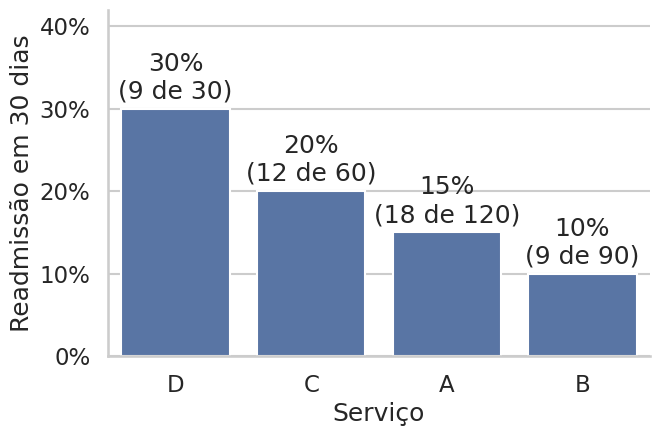

In [39]:
# Cria uma figura com tamanho de 7 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(7, 4.5))

# Cria um gráfico de barras com a taxa de readmissão por serviço
sns.barplot(data=taxa, x="servico", y="taxa",
            ax=ax)

# Cria os rótulos com a porcentagem e o número de readmissões
# Exemplo: 25% (10 de 40)
rotulos = [f"{s.taxa:.0%}\n({s.n} de {s.N})"
           for s in taxa.itertuples()]

ax.bar_label(
    ax.containers[0],  # Seleciona o único conjunto de barras
    labels=rotulos,    # Textos exibidos sobre as barras
    padding=4          # Distância dos rótulos às barras, em pontos
)

# Adiciona uma margem vertical de 40% para acomodar os rótulos
ax.margins(y=0.4)

# Formata os valores do eixo Y como porcentagens
ax.yaxis.set_major_formatter("{x:.0%}")

# Define os títulos dos eixos X e Y
ax.set(xlabel="Serviço",
       ylabel="Readmissão em 30 dias")

# Remove as bordas superior e direita do gráfico
sns.despine()

### Contagens com n (%)

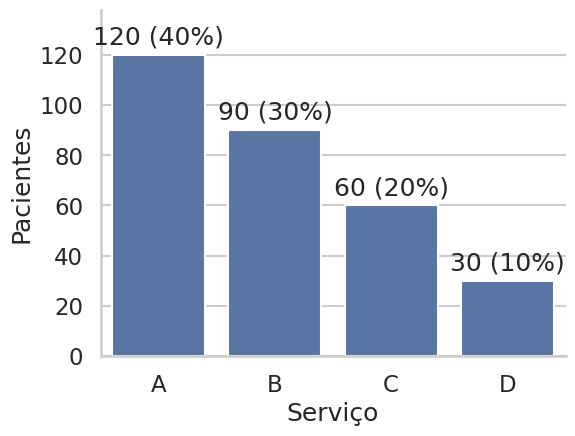

In [40]:
# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Conta os pacientes por serviço e define a ordem do maior para o menor
# value_counts() = conta quantas vezes cada serviço aparece
# .index = retorna os nomes dos serviços na ordem das contagens
ordem = df["servico"].value_counts().index

# Cria um gráfico de barras com a quantidade de pacientes por serviço
# data=df     = DataFrame utilizado
# x="servico" = coluna cujas categorias serão contadas
# order=ordem = define a ordem das barras
# ax=ax       = define os eixos onde o gráfico será desenhado
sns.countplot(data=df, x="servico", order=ordem,
              ax=ax)

# Seleciona o primeiro conjunto de barras do gráfico
barras = ax.containers[0]

# Soma as alturas das barras para obter o total de pacientes contabilizados
# datavalues = valores numéricos (contagens) representados pelas barras
total = barras.datavalues.sum()

# Adiciona rótulos acima de cada barra
# barras          = conjunto de barras que receberá os rótulos
# padding=4       = distância entre a barra e o rótulo, em pontos
# labels          = lista de textos exibidos acima das barras
# v               = quantidade de pacientes representada por cada barra
# v:.0f           = quantidade formatada sem casas decimais
# v / total:.0%   = proporção em relação ao total, formatada como porcentagem
# Exemplo: 150 (30%)
ax.bar_label(barras, padding=4, labels=[
    f"{v:.0f} ({v / total:.0%})"
    for v in barras.datavalues])

# Adiciona uma margem vertical de 15% para acomodar os rótulos
ax.margins(y=0.15)

# Define os títulos dos eixos X e Y
ax.set(xlabel="Serviço", ylabel="Pacientes")

# Remove as bordas superior e direita do gráfico
sns.despine()

###  Mapa de calor com % e n em cada célula



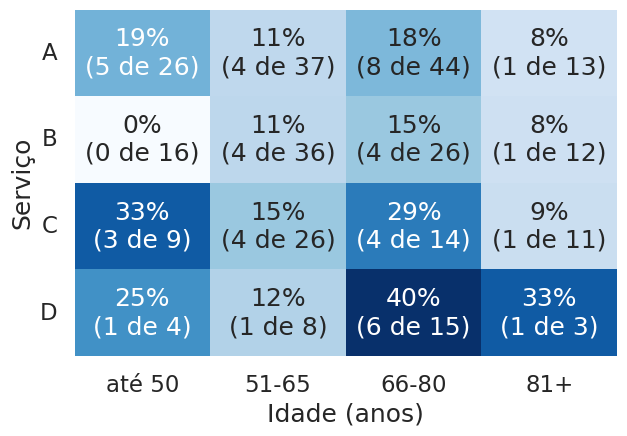

In [41]:
# Define os limites das faixas etárias
# Os intervalos são (0, 50], (50, 65], (65, 80] e (80, 120]
cortes = [0, 50, 65, 80, 120]

# Define os nomes das faixas etárias
faixas = ["até 50", "51-65", "66-80", "81+"]

# Cria uma nova coluna categorizando os pacientes por faixa etária
# df["idade"]  = coluna com as idades dos pacientes
# cortes       = limites utilizados para dividir as idades
# labels       = nomes atribuídos a cada intervalo
df["faixa"] = pd.cut(df["idade"], cortes, labels=faixas)

# Agrupa os registros por serviço e faixa etária
# observed=True = considera apenas combinações de categorias presentes nos dados
g = df.groupby(["servico", "faixa"], observed=True)

# Calcula as readmissões para cada combinação de serviço e faixa etária
# n = número de readmissões (soma dos valores 1)
# N = número total de registros não nulos na coluna de readmissão
res = g["readmissao_30d"].agg(n="sum", N="count")

# Cria os rótulos que serão exibidos no mapa de calor
# zip() = combina os valores das colunas n e N
# n / N:.0% = taxa de readmissão formatada como porcentagem
# \n = quebra de linha entre a porcentagem e as quantidades
# Exemplo: 25% (10 de 40)
res["rot"] = [f"{n / N:.0%}\n({n} de {N})"
              for n, N in zip(res["n"], res["N"])]

# Cria uma figura com tamanho de 7 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(7, 4.5))

# Cria um mapa de calor com as taxas de readmissão
# res["n"] / res["N"] = calcula a taxa de readmissão de cada grupo
# .unstack()          = transforma as faixas etárias em colunas
# annot               = define os textos exibidos dentro de cada célula
# fmt=""              = utiliza os rótulos como textos, sem formatação numérica adicional
# cmap="Blues"        = utiliza uma escala de cores azuis
# vmin=0              = define o valor mínimo da escala de cores como zero
# cbar=False          = remove a barra lateral que representa a escala de cores
# ax=ax               = define os eixos onde o gráfico será desenhado
sns.heatmap((res["n"] / res["N"]).unstack(),
            annot=res["rot"].unstack(), fmt="",
            cmap="Blues", vmin=0, cbar=False, ax=ax)

# Define os títulos dos eixos X e Y
ax.set(xlabel="Idade (anos)", ylabel="Serviço")

# Configura a rotação dos rótulos do eixo Y
# axis="y"  = seleciona o eixo vertical
# rotation=0 = mantém os nomes dos serviços na horizontal
ax.tick_params(axis="y", rotation=0)

## 02 · Distribuições comparáveis

### Grupos de tamanhos diferentes, na mesma escala

[Text(0.5, 0, 'Tempo de internação (dias)'), Text(0, 0.5, '% do grupo')]

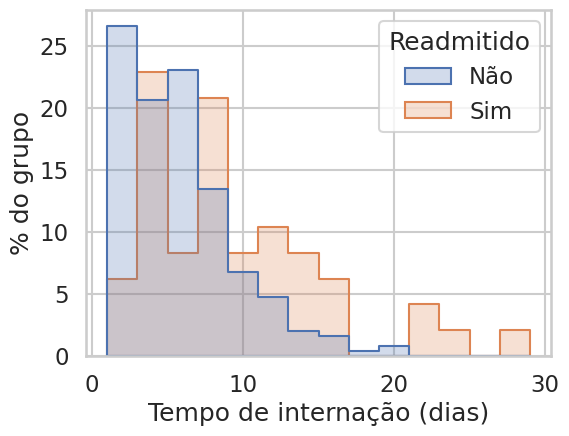

In [42]:
# map() = substitui os valores conforme o dicionário informado
# 0 = "Não" (paciente não readmitido)
# 1 = "Sim" (paciente readmitido)
df["Readmitido"] = df["readmissao_30d"].map(
    {0: "Não", 1: "Sim"})

# Armazena o nome da coluna com o tempo de internação
dias = "tempo_internacao_dias"

# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um histograma comparando o tempo de internação entre os grupos
# data=df             = DataFrame utilizado
# x=dias              = coluna com os tempos de internação
# hue="Readmitido"    = separa os dados em grupos por readmissão
# hue_order           = define a ordem dos grupos na legenda
# stat="percent"      = apresenta as frequências em porcentagem
# common_norm=False   = normaliza cada grupo separadamente (cada um soma 100%)
# element="step"      = desenha os histogramas com contornos, sem barras preenchidas
# binwidth=2          = define a largura dos intervalos como 2 dias
# ax=ax               = define os eixos onde o gráfico será desenhado
sns.histplot(data=df, x=dias, hue="Readmitido",
             hue_order=["Não", "Sim"],
             stat="percent", common_norm=False,
             element="step", binwidth=2, ax=ax)

# Define os títulos dos eixos X e Y
# xlabel = nome exibido no eixo horizontal
# ylabel = porcentagem de pacientes dentro de cada grupo
ax.set(xlabel="Tempo de internação (dias)",
       ylabel="% do grupo")

### Quantos ficaram até x dias

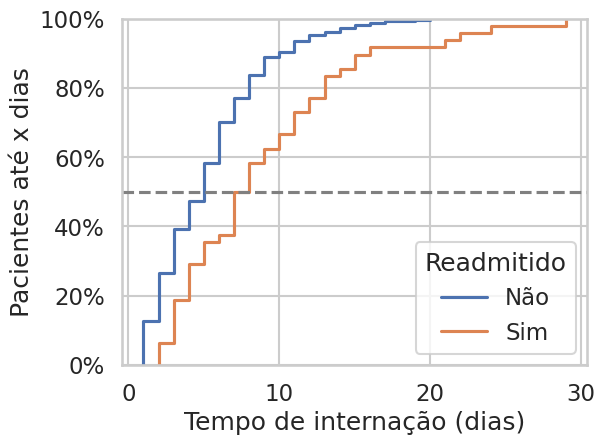

In [43]:
# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um gráfico de distribuição acumulada empírica (ECDF)
# data=df          = DataFrame utilizado
# x=dias           = coluna com os tempos de internação
# hue="Readmitido" = separa as curvas por grupo de readmissão
# hue_order        = define a ordem dos grupos na legenda
# ax=ax            = define os eixos onde o gráfico será desenhado
# ECDF             = mostra a proporção acumulada de pacientes com internação de até x dias
sns.ecdfplot(data=df, x=dias, hue="Readmitido",
             hue_order=["Não", "Sim"], ax=ax)

# Adiciona uma linha horizontal na altura de 50%
# 0.5           = posição da linha no eixo Y (50%)
# color="gray"  = define a cor cinza
# linestyle="--" = utiliza uma linha tracejada
# A interseção com cada curva permite identificar a mediana do grupo
ax.axhline(0.5, color="gray", linestyle="--")

# Formata os valores do eixo Y como porcentagens
# Exemplo: 0.5 será exibido como 50%
ax.yaxis.set_major_formatter("{x:.0%}")

# Define os títulos dos eixos X e Y
# xlabel = tempo de internação em dias
# ylabel = proporção acumulada de pacientes com internação de até x dias
ax.set(xlabel="Tempo de internação (dias)",
       ylabel="Pacientes até x dias")

# Posiciona a legenda no canto inferior direito do gráfico
# ax            = gráfico cuja legenda será modificada
# "lower right" = posição inferior direita
sns.move_legend(ax, "lower right")

### Violino: a forma da distribuição

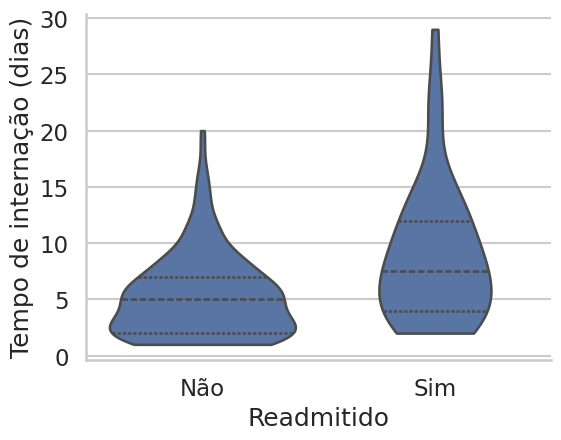

In [44]:
# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um gráfico de violino para comparar o tempo de internação entre os grupos
# data=df          = DataFrame utilizado
# x="Readmitido"   = coluna que separa os pacientes por readmissão
# y=dias           = coluna com os tempos de internação
# order            = define a ordem dos grupos no eixo X
# inner="quart"    = exibe as linhas dos quartis (25%, 50% e 75%) dentro dos violinos
# cut=0            = limita os violinos aos valores mínimo e máximo observados
# ax=ax            = define os eixos onde o gráfico será desenhado
# A largura do violino representa a densidade estimada dos dados em cada valor
sns.violinplot(data=df, x="Readmitido", y=dias,
               order=["Não", "Sim"],
               inner="quart", cut=0, ax=ax)

# Define o título do eixo Y como tempo de internação em dias
ax.set(ylabel="Tempo de internação (dias)")

# Remove as bordas superior e direita do gráfico
sns.despine()

## 03 · Incerteza e limites

### A taxa com o seu intervalo

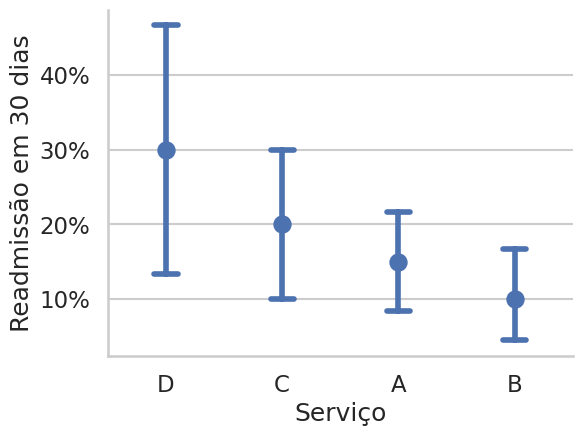

In [45]:
# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um gráfico de pontos com as taxas de readmissão por serviço
# data=df              = DataFrame utilizado
# x="servico"           = coluna que identifica os serviços
# y="readmissao_30d"    = coluna binária (0 = não readmitido, 1 = readmitido)
# order=taxa["servico"] = define a ordem dos serviços conforme a tabela taxa
# errorbar=("ci", 95)   = calcula intervalos de confiança de 95% por bootstrap
# seed=42              = fixa a semente aleatória para reproduzir os resultados
# capsize=0.2          = define a largura das extremidades das barras de erro
# linestyle="none"     = impede que os pontos sejam conectados por linhas
# ax=ax                = define os eixos onde o gráfico será desenhado
# Cada ponto representa a taxa média de readmissão do respectivo serviço
sns.pointplot(data=df, x="servico",
              y="readmissao_30d",
              order=taxa["servico"],
              errorbar=("ci", 95), seed=42,
              capsize=0.2, linestyle="none",
              ax=ax)

# Formata os valores do eixo Y como porcentagens
# Exemplo: 0.25 será exibido como 25%
ax.yaxis.set_major_formatter("{x:.0%}")

# Define os títulos dos eixos X e Y
# xlabel = nome dos serviços
# ylabel = taxa de readmissão em até 30 dias
ax.set(xlabel="Serviço",
       ylabel="Readmissão em 30 dias")

# Remove as bordas superior e direita do gráfico
sns.despine()

### Tendência com faixa de incerteza

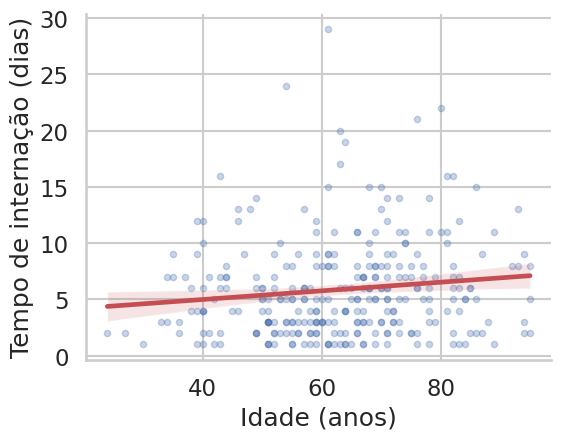

In [46]:
# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um gráfico de dispersão com uma linha de regressão linear
# data=df                        = DataFrame utilizado
# x="idade"                      = coluna com as idades dos pacientes (eixo X)
# y=dias                         = coluna com os tempos de internação (eixo Y)
# ax=ax                          = define os eixos onde o gráfico será desenhado
# scatter_kws                    = dicionário que configura a aparência dos pontos
#   "alpha": 0.3                 = define a transparência dos pontos (0 = invisível, 1 = opaco)
#   "s": 20                      = define a área dos pontos em pontos²
# line_kws                       = dicionário que configura a aparência da linha de regressão
#   "color": "#c44e52"           = define a cor da linha pelo código hexadecimal
# A linha representa a tendência linear estimada entre idade e tempo de internação
sns.regplot(data=df, x="idade", y=dias, ax=ax,
            scatter_kws={"alpha": 0.3, "s": 20},
            line_kws={"color": "#c44e52"})

# Define os títulos dos eixos X e Y
# xlabel = idade dos pacientes em anos
# ylabel = tempo de internação em dias
ax.set(xlabel="Idade (anos)",
       ylabel="Tempo de internação (dias)")

# Remove as bordas superior e direita do gráfico
sns.despine()

## 04 · Destaque e mensagem

### Cor para o achado, cinza para o contexto



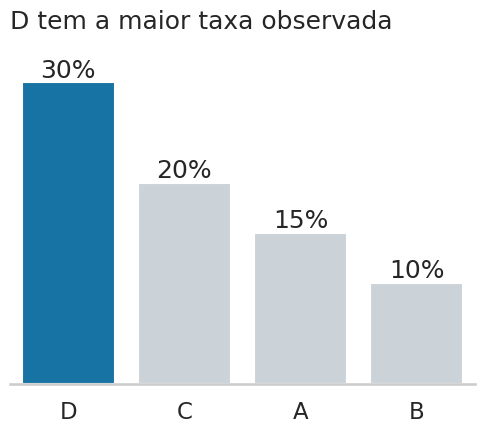

In [47]:
# Cria um dicionário associando cada serviço a uma cor
# s               = nome de cada serviço presente na tabela taxa
# taxa["servico"] = coluna com os nomes dos serviços
# "#c9d3db"       = código hexadecimal da cor cinza-azulada
cores = {s: "#c9d3db" for s in taxa["servico"]}

# Altera a cor do serviço D para destacá-lo
# "D"       = serviço que receberá uma cor diferente
# "#007bba" = código hexadecimal da cor azul
cores["D"] = "#007bba"

# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um gráfico de barras com as taxas de readmissão por serviço
# data=taxa      = DataFrame utilizado
# x="servico"    = coluna com os nomes dos serviços
# y="taxa"       = coluna com as taxas de readmissão
# hue="servico"  = separa as barras por serviço para permitir cores diferentes
# palette=cores  = utiliza as cores definidas no dicionário
# legend=False   = oculta a legenda
# ax=ax          = define os eixos onde o gráfico será desenhado
sns.barplot(data=taxa, x="servico", y="taxa",
            hue="servico", palette=cores,
            legend=False, ax=ax)

# Percorre todos os conjuntos de barras existentes no gráfico
# ax.containers = lista de conjuntos de barras
# barras        = conjunto selecionado em cada iteração
for barras in ax.containers:

    # Adiciona os valores percentuais acima das barras
    # barras       = conjunto de barras que receberá os rótulos
    # fmt="{:.0%}" = formata os valores como porcentagens sem casas decimais
    # Exemplo: 0.25 será exibido como 25%
    ax.bar_label(barras, fmt="{:.0%}")

# Adiciona uma margem vertical de 15% para acomodar os rótulos
ax.margins(y=0.15)

# Define o título do gráfico
# "D tem a maior taxa observada" = texto apresentado no título
# loc="left"                     = alinha o título à esquerda
ax.set_title("D tem a maior taxa observada",
             loc="left")

# Configura os eixos do gráfico
# xlabel="" = remove o título do eixo X
# ylabel="" = remove o título do eixo Y
# yticks=[] = remove os valores e as marcações do eixo Y
ax.set(xlabel="", ylabel="", yticks=[])

# Remove as bordas superior, direita e esquerda do gráfico
# left=True = remove também a borda esquerda
sns.despine(left=True)

### O mesmo grupo, a mesma cor



[Text(0.5, 0, 'Dias'), Text(0, 0.5, '')]

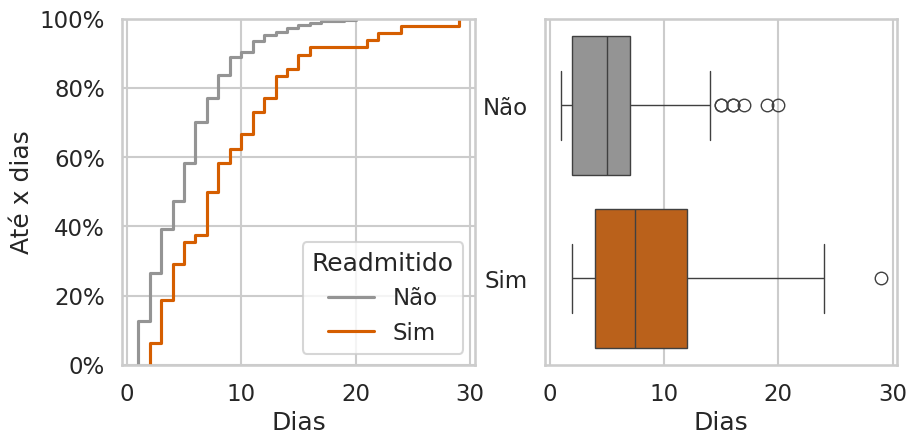

In [48]:
# Seleciona a paleta de cores "colorblind", adequada para pessoas com daltonismo
paleta = sns.color_palette("colorblind")

# Cria um dicionário associando cada grupo a uma cor da paleta
# "Não"      = pacientes não readmitidos
# "Sim"      = pacientes readmitidos
# paleta[7]  = oitava cor da paleta (índice 7)
# paleta[3]  = quarta cor da paleta (índice 3)
cor = {"Não": paleta[7], "Sim": paleta[3]}

# Define a ordem dos grupos nos gráficos
grupos = ["Não", "Sim"]

# Cria uma figura com dois gráficos lado a lado
# 1                = número de linhas
# 2                = número de colunas
# figsize=(10, 4.5) = tamanho total da figura em polegadas
# fig              = representa a figura completa
# axes             = conjunto de eixos dos dois gráficos
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Cria um gráfico de distribuição acumulada empírica (ECDF)
# data=df          = DataFrame utilizado
# x=dias           = coluna com os tempos de internação
# hue="Readmitido" = separa as curvas conforme a readmissão
# hue_order=grupos = define a ordem dos grupos na legenda
# palette=cor      = utiliza as cores definidas no dicionário
# ax=axes[0]       = desenha o gráfico no primeiro eixo (à esquerda)
# ECDF             = mostra a proporção de pacientes internados por até x dias
sns.ecdfplot(data=df, x=dias, hue="Readmitido",
             hue_order=grupos, palette=cor,
             ax=axes[0])

# Cria um boxplot para comparar o tempo de internação entre os grupos
# data=df          = DataFrame utilizado
# x=dias           = coluna com os tempos de internação
# y="Readmitido"   = separa os pacientes por grupo no eixo Y
# hue="Readmitido" = permite atribuir uma cor diferente para cada grupo
# order=grupos     = define a ordem dos grupos no eixo Y
# palette=cor      = utiliza as mesmas cores do gráfico ECDF
# legend=False     = oculta a legenda do boxplot
# ax=axes[1]       = desenha o gráfico no segundo eixo (à direita)
# O boxplot apresenta mediana, quartis, dispersão e possíveis valores atípicos
sns.boxplot(data=df, x=dias, y="Readmitido",
            hue="Readmitido", order=grupos,
            palette=cor, legend=False, ax=axes[1])

# Formata os valores do eixo Y do primeiro gráfico como porcentagens
# Exemplo: 0.5 será exibido como 50%
axes[0].yaxis.set_major_formatter("{x:.0%}")

# Define os títulos dos eixos do primeiro gráfico (ECDF)
# xlabel="Dias"    = título do eixo X
# ylabel="Até x dias" = indica a proporção acumulada até x dias
axes[0].set(xlabel="Dias", ylabel="Até x dias")

# Define os títulos dos eixos do segundo gráfico (boxplot)
# xlabel="Dias" = título do eixo X
# ylabel=""     = remove o título do eixo Y, mantendo os nomes dos grupos
axes[1].set(xlabel="Dias", ylabel="")

###  Facetas: o mesmo gráfico em cada estrato



Text(0.5, 0.01, 'Readmitido')

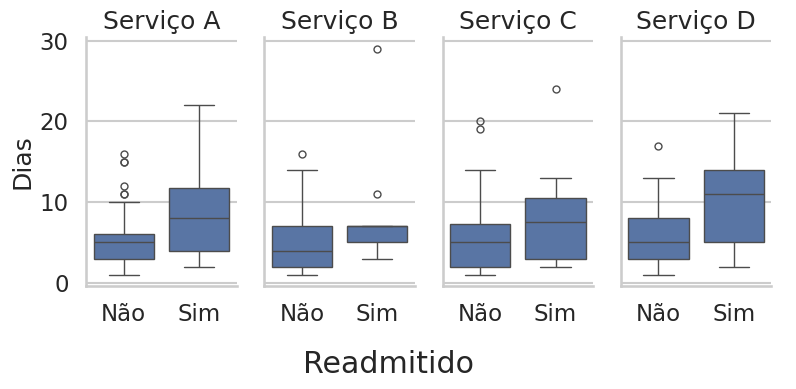

In [49]:
# Cria uma figura com vários boxplots, separados por serviço
# data=df            = DataFrame utilizado
# x="Readmitido"     = coluna que separa os pacientes por readmissão
# y=dias             = coluna com os tempos de internação
# col="servico"      = cria um gráfico separado para cada serviço
# order=["Não","Sim"] = define a ordem dos grupos no eixo X
# kind="box"         = define o tipo de gráfico como boxplot
# height=4           = altura de cada gráfico em polegadas
# aspect=0.5         = proporção largura/altura de cada gráfico
#                      (largura = 4 × 0.5 = 2 polegadas)
# g                  = objeto FacetGrid que contém todos os gráficos
g = sns.catplot(data=df, x="Readmitido",
                y=dias, col="servico",
                order=["Não", "Sim"],
                kind="box", height=4,
                aspect=0.5)

# Define os títulos individuais dos gráficos
# "Serviço {col_name}" = texto exibido acima de cada gráfico
# {col_name}           = substituído automaticamente pelo nome do serviço
# Exemplo: "Serviço A", "Serviço B", "Serviço C"
g.set_titles("Serviço {col_name}")

# Define os títulos dos eixos de cada gráfico
# ""     = remove os títulos individuais do eixo X
# "Dias" = define o título do eixo Y como "Dias"
g.set_axis_labels("", "Dias")

# Adiciona um título geral para o eixo X da figura completa
# g.figure  = acessa a figura que contém todos os gráficos
# supxlabel = adiciona um único título horizontal para toda a figura
# "Readmitido" = texto exibido como título geral do eixo X
g.figure.supxlabel("Readmitido")

###  Anote a leitura que importa



[Text(0.5, 0, 'Dias'), Text(0, 0.5, 'Pacientes até x dias')]

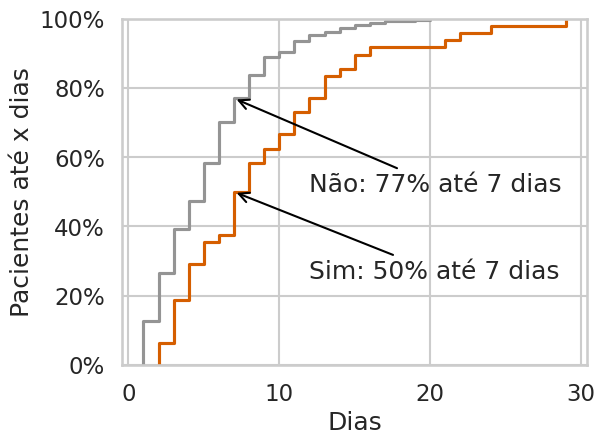

In [50]:
# Calcula a proporção de pacientes com internação de até 7 dias por grupo
# df[dias] <= 7          = verifica se o tempo de internação é menor ou igual a 7 dias
#                         (True = 1 e False = 0 no cálculo da média)
# groupby(df["Readmitido"]) = agrupa os resultados por readmissão ("Não" e "Sim")
# mean()                = calcula a proporção de pacientes com até 7 dias de internação
# p7                    = série com as proporções calculadas para cada grupo
p7 = (df[dias] <= 7).groupby(df["Readmitido"]).mean()

# Cria uma figura com tamanho de 6 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(6, 4.5))

# Cria um gráfico de distribuição acumulada empírica (ECDF)
# data=df          = DataFrame utilizado
# x=dias           = coluna com os tempos de internação
# hue="Readmitido" = separa as curvas por grupo de readmissão
# hue_order=grupos = define a ordem dos grupos ("Não" e "Sim")
# palette=cor      = utiliza as cores definidas anteriormente
# legend=False     = oculta a legenda do gráfico
# ax=ax            = define os eixos onde o gráfico será desenhado
sns.ecdfplot(data=df, x=dias, hue="Readmitido",
             hue_order=grupos, palette=cor,
             legend=False, ax=ax)

# Define as características das setas utilizadas nas anotações
# arrowstyle="->" = utiliza uma seta com ponta na extremidade
# color="black"   = define a cor preta para as setas
seta = {"arrowstyle": "->", "color": "black"}

# Percorre os dois grupos e define a posição vertical de cada anotação
# grupo   = nome do grupo analisado ("Não" ou "Sim")
# y_texto = posição vertical do texto no gráfico
# ("Não", 0.5)  = posiciona o texto do grupo "Não" na altura de 50%
# ("Sim", 0.25) = posiciona o texto do grupo "Sim" na altura de 25%
for grupo, y_texto in [("Não", 0.5), ("Sim", 0.25)]:

    # Obtém a proporção de pacientes com internação de até 7 dias no grupo
    # p7[grupo] = acessa a proporção calculada para o grupo atual
    p = p7[grupo]

    # Adiciona uma anotação com texto e seta apontando para a curva
    # f"{grupo}: {p:.0%} até 7 dias" = texto com o grupo e sua porcentagem
    # xy=(7, p)       = coordenadas do ponto indicado pela seta
    #                   (7 dias no eixo X e proporção p no eixo Y)
    # xytext=(12, y_texto) = coordenadas onde o texto será posicionado
    #                        (12 dias no eixo X e y_texto no eixo Y)
    # arrowprops=seta = aplica as características da seta definidas anteriormente
    ax.annotate(f"{grupo}: {p:.0%} até 7 dias",
                xy=(7, p), xytext=(12, y_texto),
                arrowprops=seta)

# Formata os valores do eixo Y como porcentagens
# Exemplo: 0.5 será exibido como 50%
ax.yaxis.set_major_formatter("{x:.0%}")

# Define os títulos dos eixos X e Y
# xlabel="Dias" = tempo de internação em dias
# ylabel        = proporção acumulada de pacientes com internação de até x dias
ax.set(xlabel="Dias", ylabel="Pacientes até x dias")

###  Título informativo e o código da figura



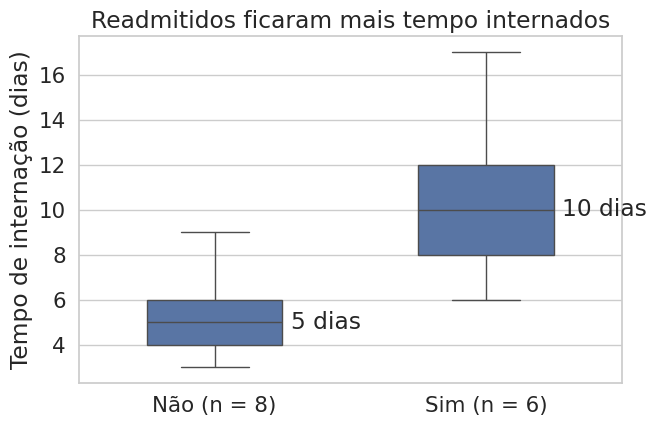

In [51]:
# Configura a aparência dos gráficos
# style="whitegrid" = utiliza fundo branco com linhas de grade
# font_scale=1.4    = aumenta o tamanho das fontes em 40% em relação ao padrão
sns.set_theme(style="whitegrid", font_scale=1.4)

# Agrupa os registros conforme a condição de readmissão
# df_rev                = DataFrame utilizado
# groupby()             = separa os dados em grupos
# "readmissao_30d"      = coluna que identifica os grupos (0 = Não, 1 = Sim)
g = df_rev.groupby("readmissao_30d")

# Calcula o tamanho e a mediana de cada grupo
# g.size()            = número de registros em cada grupo
# g["tempo"].median() = mediana do tempo de internação de cada grupo
# n                   = série com a quantidade de registros por grupo
# med                 = série com as medianas dos tempos de internação
n, med = g.size(), g["tempo"].median()

# Cria uma figura com tamanho de 7 × 4,5 polegadas
fig, ax = plt.subplots(figsize=(7, 4.5))

# Cria um boxplot para comparar o tempo de internação entre os grupos
# data=df_rev          = DataFrame utilizado
# x="readmissao_30d"   = coluna que separa os grupos de readmissão
# y="tempo"            = coluna com os tempos de internação
# width=0.5            = define a largura das caixas
# ax=ax                = define os eixos onde o gráfico será desenhado
# O boxplot apresenta mediana, quartis, dispersão e possíveis valores atípicos
sns.boxplot(data=df_rev, x="readmissao_30d",
            y="tempo", width=0.5, ax=ax)

# Define o título do gráfico
ax.set_title("Readmitidos ficaram mais tempo internados")

# Personaliza os rótulos do eixo X
# [0, 1]  = posições das duas categorias no eixo X
# labels  = textos exibidos em cada posição
# n[0]    = quantidade de registros não readmitidos
# n[1]    = quantidade de registros readmitidos
# Exemplo: "Não (n = 100)" e "Sim (n = 40)"
ax.set_xticks([0, 1], labels=[f"Não (n = {n[0]})",
                              f"Sim (n = {n[1]})"])

# Define os títulos dos eixos X e Y
# xlabel="" = remove o título do eixo X
# ylabel    = indica o tempo de internação em dias
ax.set(xlabel="", ylabel="Tempo de internação (dias)")

# Percorre as medianas dos dois grupos
# enumerate(med) = retorna a posição e a mediana de cada grupo
# x              = posição do grupo no eixo X (0 ou 1)
# m              = mediana do tempo de internação do grupo
for x, m in enumerate(med):

    # Adiciona um texto indicando a mediana de cada grupo
    # x + 0.28       = posiciona o texto à direita do centro da caixa
    # m              = posiciona o texto na altura da mediana
    # f"{m:.0f} dias" = formata a mediana sem casas decimais
    # va="center"    = centraliza verticalmente o texto na posição indicada
    ax.text(x + 0.28, m, f"{m:.0f} dias", va="center")

## Tudo junto

### Antes e depois, com as técnicas de hoje



<Axes: xlabel='servico', ylabel='readmissao_30d'>

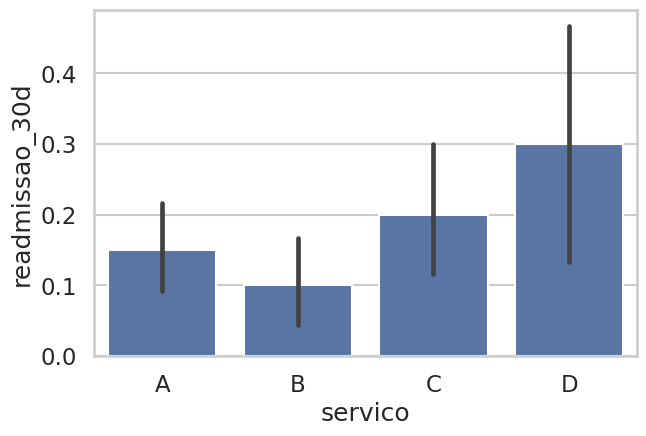

In [52]:
sns.set_theme(style="whitegrid", context="talk")

# Antes: o barplot padrão, direto da base
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=df, x="servico", y="readmissao_30d", ax=ax)

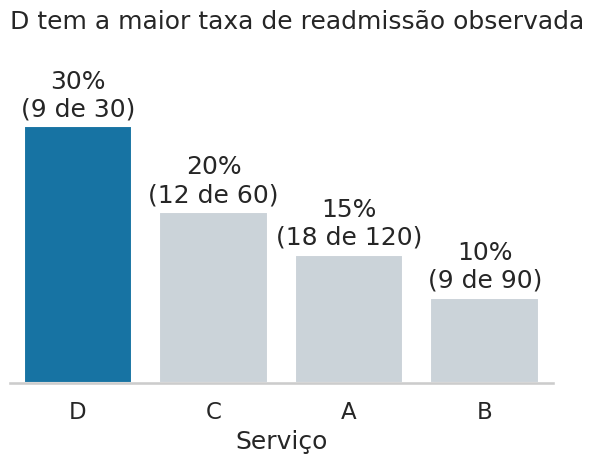

In [53]:
# Depois: as técnicas da aula no mesmo dado
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=taxa, x="servico", y="taxa",
            hue="servico", palette=cores,
            legend=False, ax=ax)
for barras, rotulo in zip(ax.containers, rotulos):
    ax.bar_label(barras, labels=[rotulo], padding=4)
ax.margins(y=0.35)
ax.set_title("D tem a maior taxa de readmissão observada",
             loc="left")
ax.set(xlabel="Serviço", ylabel="", yticks=[])
sns.despine(left=True)
fig.savefig("depois.png", dpi=300, bbox_inches="tight")